In [2]:
import numpy as np
import pandas as pd

data = np.load("../data/heston_surfaces.npz")
print(data.files)

X_train = pd.DataFrame(data['X_train'])
Y_train = pd.DataFrame(data['Y_train'])
X_test = pd.DataFrame(data['X_test'])
Y_test = pd.DataFrame(data['Y_test'])
X_val = pd.DataFrame(data['X_val'])
Y_val = pd.DataFrame(data['Y_val'])

moneyness = data["moneyness_grid"]
maturity  = data["maturity_grid"]

X_train.columns = ["kappa", "theta", "xi", "rho", "v0"]

def surface(i, Y=Y_train):
    """Fold row i of a flat 63-column frame back into its 9x7 grid."""
    return pd.DataFrame(Y.iloc[i].values.reshape(len(moneyness), len(maturity)),
                        index=pd.Index(moneyness, name="moneyness"),
                        columns=pd.Index(maturity, name="maturity"))

for i in range(3):
    print(f"Surface {i}:\n", surface(i).round(4), "\n")

['X_train', 'Y_train', 'X_test', 'Y_test', 'X_val', 'Y_val', 'moneyness_grid', 'maturity_grid']
Surface 0:
 maturity     0.10    0.25    0.50    1.00    1.50    2.00    3.00
moneyness                                                        
0.70       0.5280  0.5123  0.4949  0.4779  0.4702  0.4660  0.4614
0.80       0.4933  0.4825  0.4719  0.4628  0.4592  0.4573  0.4554
0.90       0.4602  0.4550  0.4511  0.4495  0.4495  0.4497  0.4501
0.95       0.4444  0.4420  0.4415  0.4434  0.4451  0.4462  0.4477
1.00       0.4290  0.4295  0.4324  0.4376  0.4409  0.4430  0.4454
1.05       0.4142  0.4177  0.4238  0.4321  0.4369  0.4398  0.4432
1.10       0.4004  0.4066  0.4157  0.4270  0.4331  0.4369  0.4411
1.20       0.3767  0.3868  0.4009  0.4174  0.4261  0.4313  0.4372
1.30       0.3600  0.3708  0.3880  0.4088  0.4197  0.4263  0.4337 

Surface 1:
 maturity     0.10    0.25    0.50    1.00    1.50    2.00    3.00
moneyness                                                        
0.70       0.3834  0

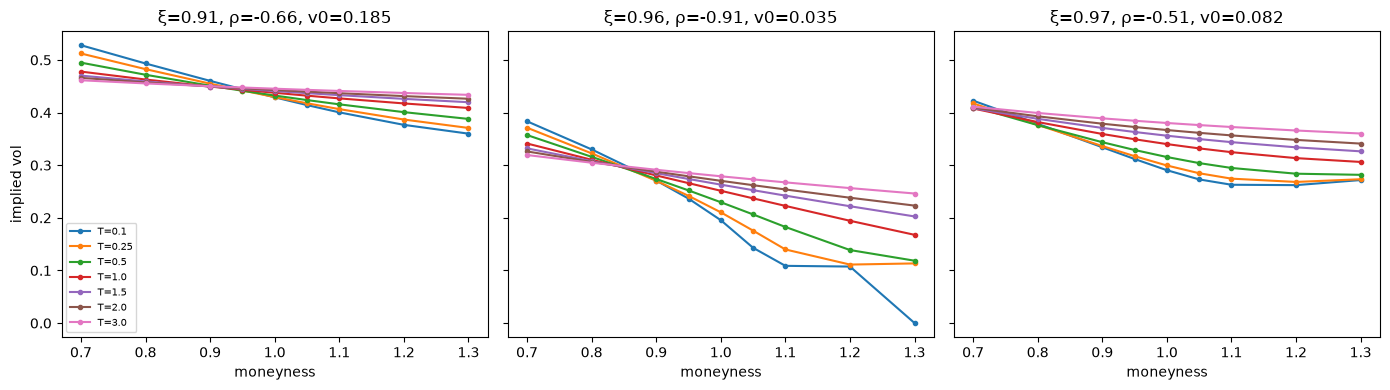

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, i in zip(axes, [0, 1, 2]):
    s = surface(i)
    for T in maturity:
        ax.plot(moneyness, s[T], marker=".", label=f"T={T}")
    p = X_train.iloc[i]
    ax.set_title(f"ξ={p.xi:.2f}, ρ={p.rho:.2f}, v0={p.v0:.3f}")
    ax.set_xlabel("moneyness")
axes[0].set_ylabel("implied vol")
axes[0].legend(fontsize=7)
plt.tight_layout()

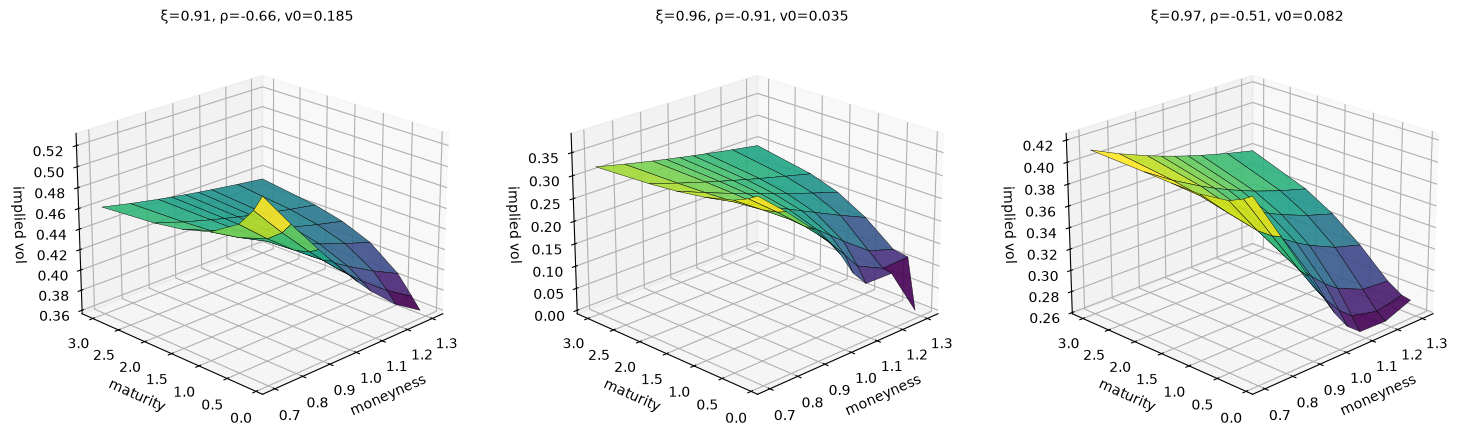

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

M, T = np.meshgrid(moneyness, maturity, indexing="ij")

fig = plt.figure(figsize=(15, 4.5))
for n, i in enumerate([0, 1, 2]):
    ax = fig.add_subplot(1, 3, n + 1, projection="3d")
    ax.plot_surface(M, T, surface(i).values, cmap="viridis",
                    edgecolor="k", linewidth=0.3, alpha=0.9)
    p = X_train.iloc[i]
    ax.set_title(f"ξ={p.xi:.2f}, ρ={p.rho:.2f}, v0={p.v0:.3f}", fontsize=10)
    ax.set_xlabel("moneyness"); ax.set_ylabel("maturity"); ax.set_zlabel("implied vol")
    ax.view_init(elev=22, azim=-135)
plt.tight_layout()